In [ ]:
import pandas as pd
df = pd.read_csv('/Users/ignacyboczula/Desktop/statystyka/projekt_statystyka/Maths.csv', sep=';')


308

In [56]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import norm

# Wczytanie danych i obliczenia
df = pd.read_csv('Maths.csv', sep=';')
df['Suma_G'] = df['G1'] + df['G2'] + df['G3']
mu = df['Suma_G'].mean()
std = df['Suma_G'].std()

# Styl minimalistyczny
sns.set_theme(style="white", font_scale=1.2)

# ==========================================
# WYKRES 1: TYLKO HISTOGRAM (BEZ GĘSTOŚCI)
# ==========================================
fig1, ax1 = plt.subplots(figsize=(11, 6))

sns.histplot(df['Suma_G'], bins=25, kde=False, ax=ax1,
             color="#e950c0", alpha=0.65, edgecolor='white', linewidth=1.5)

# Wymuszenie osi X, aby zaczynała się równo od 0 i kończyła na 60
ax1.set_xlim(left=0, right=60)

ax1.set_title('Rozkład sumy punktów z trzech egzaminów ', fontsize=18, fontweight='bold', pad=20, color='#2d3436')
ax1.set_xlabel('Suma punktów', fontsize=14, labelpad=12, color='#2d3436')
ax1.set_ylabel('Liczba uczniów', fontsize=14, labelpad=12, color='#2d3436')

# --- DODANIE ŁADNEGO GRIDA ---
# Delikatna, przerywana siatka tylko na osi Y, schowana pod spód słupków
ax1.yaxis.grid(True, linestyle='--', color='#b2bec3', alpha=0.5)
ax1.xaxis.grid(False)
ax1.set_axisbelow(True) 

sns.despine(left=True, bottom=False)

plt.tight_layout()
# Zapis w wysokiej jakości
plt.savefig('histogram_tylko_od_zera.png', dpi=300)
plt.close(fig1)

# ==========================================
# WYKRES 2: HISTOGRAM + GĘSTOŚCI TEORETYCZNA I EMPIRYCZNA
# ==========================================
fig2, ax2 = plt.subplots(figsize=(11, 6))

sns.histplot(df['Suma_G'], bins=25, kde=False, ax=ax2, stat='density',
             color='#e950c0', alpha=0.65, edgecolor='white', linewidth=1.5)

sns.kdeplot(df['Suma_G'], ax=ax2, color="#b925c1", linewidth=3.5,
            label='Gęstość empiryczna', fill=True, alpha=0.1)

# Wymuszenie osi X
ax2.set_xlim(left=0, right=60)

xmin, xmax = ax2.get_xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
ax2.plot(x, p, color="#5930d6", linestyle='--', linewidth=2.5, label='Gęstość teoretyczna')

# Użycie symbolu matematycznego \mu w legendzie

ax2.set_title('Rozkład sumy punktów z nałożonymi gęstościami', fontsize=18, fontweight='bold', pad=20, color='#2d3436')
ax2.set_xlabel('Suma punktów', fontsize=14, labelpad=12, color='#2d3436')
ax2.set_ylabel('Gęstość prawdopodobieństwa', fontsize=14, labelpad=12, color='#2d3436')

# --- DODANIE ŁADNEGO GRIDA ---
ax2.yaxis.grid(True, linestyle='--', color='#b2bec3', alpha=0.5)
ax2.xaxis.grid(False)
ax2.set_axisbelow(True)

sns.despine(left=True, bottom=False)
ax2.legend(frameon=False, fontsize=12, loc='upper right')

plt.tight_layout()
# Zapis w wysokiej jakości
plt.savefig('histogram_gestosci_od_zera.png', dpi=300)
plt.close(fig2)

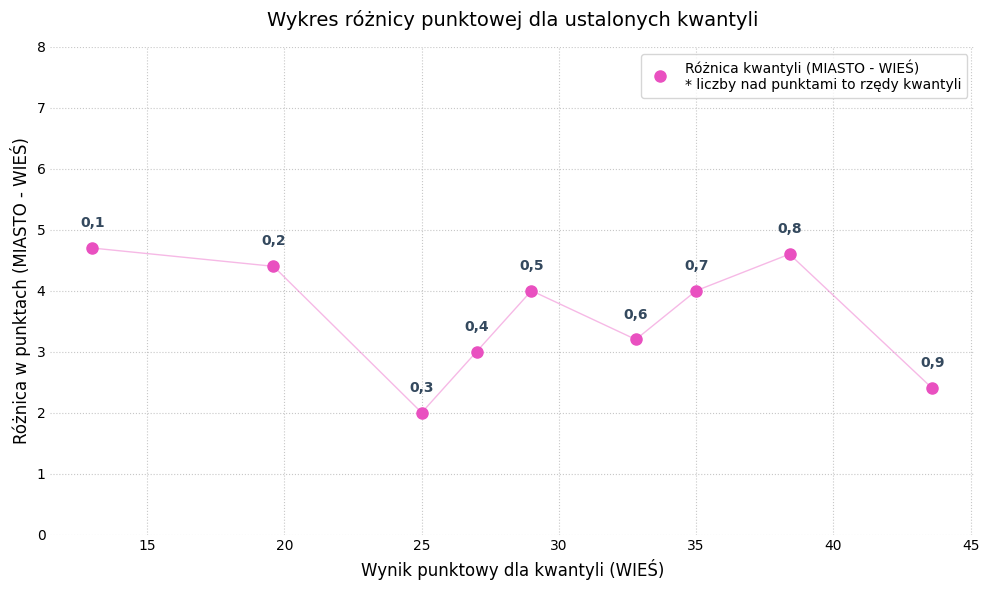

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Wczytanie i podział danych
df = pd.read_csv('Maths.csv', sep=';')
df['G_total'] = df['G1'] + df['G2'] + df['G3']
urban = df[df['address'] == 'U']['G_total'].values
rural = df[df['address'] == 'R']['G_total'].values

# Wyliczenie kwantyli i różnicy
p = np.arange(0.1, 1.0, 0.1)
q_u_emp = np.quantile(urban, p)
q_r_emp = np.quantile(rural, p)
shift_emp = q_u_emp - q_r_emp

# Rysowanie wykresu
plt.figure(figsize=(10, 6))

plt.plot(q_r_emp, shift_emp, color='#e950c0', linewidth=1, linestyle='-', alpha=0.4)
plt.plot(q_r_emp, shift_emp, marker='o', markersize=8, color='#e950c0', linestyle='',
         label='Różnica kwantyli (MIASTO - WIEŚ)\n* liczby nad punktami to rzędy kwantyli')

plt.ylim(0, 8)

for i, decil in enumerate(p):
    plt.annotate(f"0,{int(decil*10)}", (q_r_emp[i], shift_emp[i]), 
                 textcoords="offset points", xytext=(0,15), 
                 ha='center', fontsize=10, fontweight='bold', color='#34495e')

plt.xlabel('Wynik punktowy dla kwantyli (WIEŚ)', fontsize=12)
plt.ylabel('Różnica w punktach (MIASTO - WIEŚ)', fontsize=12)
plt.title('Wykres różnicy punktowej dla ustalonych kwantyli', fontsize=14, pad=15)

plt.grid(True, linestyle=':', alpha=0.7)

ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(axis='both', which='both', length=0)

plt.legend(loc='upper right')
plt.tight_layout()

# KLUCZOWA ZMIANA TUTAJ: dpi=300
plt.savefig('shift_function_final.png', dpi=300)